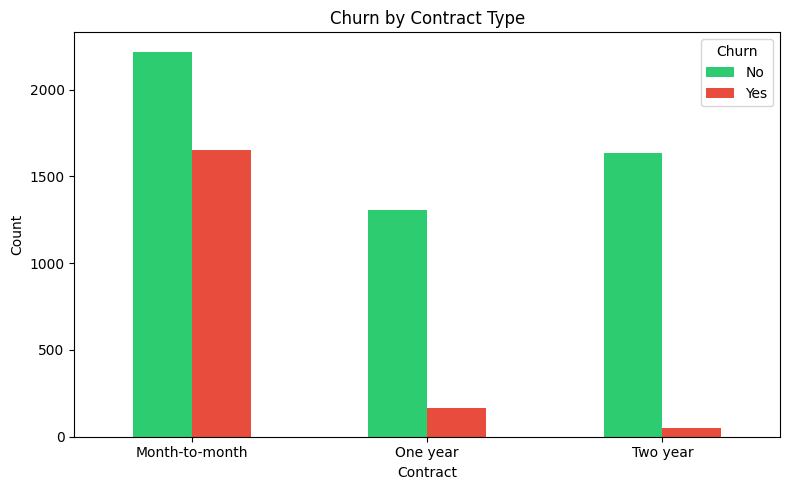

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Telco_Customer_Churn_Cleaned.csv')

ct = pd.crosstab(df['Contract'], df['Churn'])
ct.plot(kind='bar', color=['#2ecc71', '#e74c3c'], figsize=(8, 5))

plt.title('Churn by Contract Type')
plt.xlabel('Contract')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

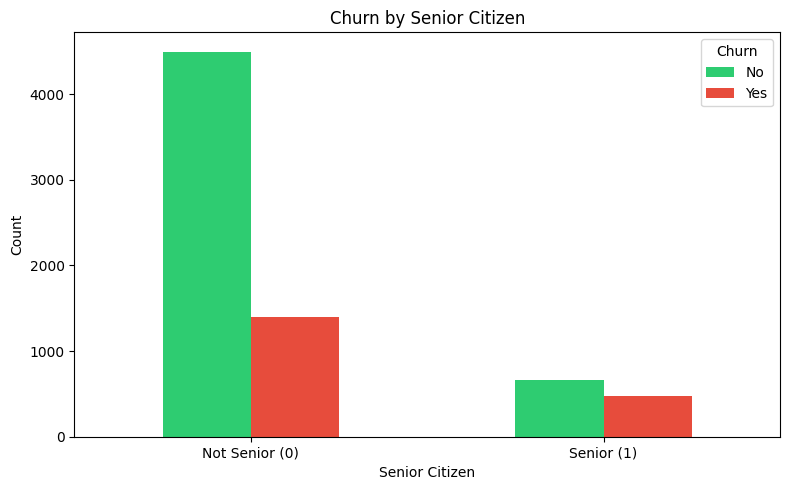

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Telco_Customer_Churn_Cleaned.csv')

ct = pd.crosstab(df['SeniorCitizen'], df['Churn'])
ct.index = ['Not Senior (0)', 'Senior (1)']
ct.plot(kind='bar', color=['#2ecc71', '#e74c3c'], figsize=(8, 5))

plt.title('Churn by Senior Citizen')
plt.xlabel('Senior Citizen')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/tmp/ipykernel_675/3202255107.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp1 = axes[0, 1].boxplot([no_net_charges, dsl_charges, fiber_charges], labels=['No Internet', 'DSL', 'Fiber optic'], patch_artist=True, widths=0.5)
/tmp/ipykernel_675/3202255107.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axes[1, 0].boxplot([t_m2m, t_1yr, t_2yr], labels=['Month-to-month', 'One year', 'Two year'], patch_artist=True, widths=0.5)


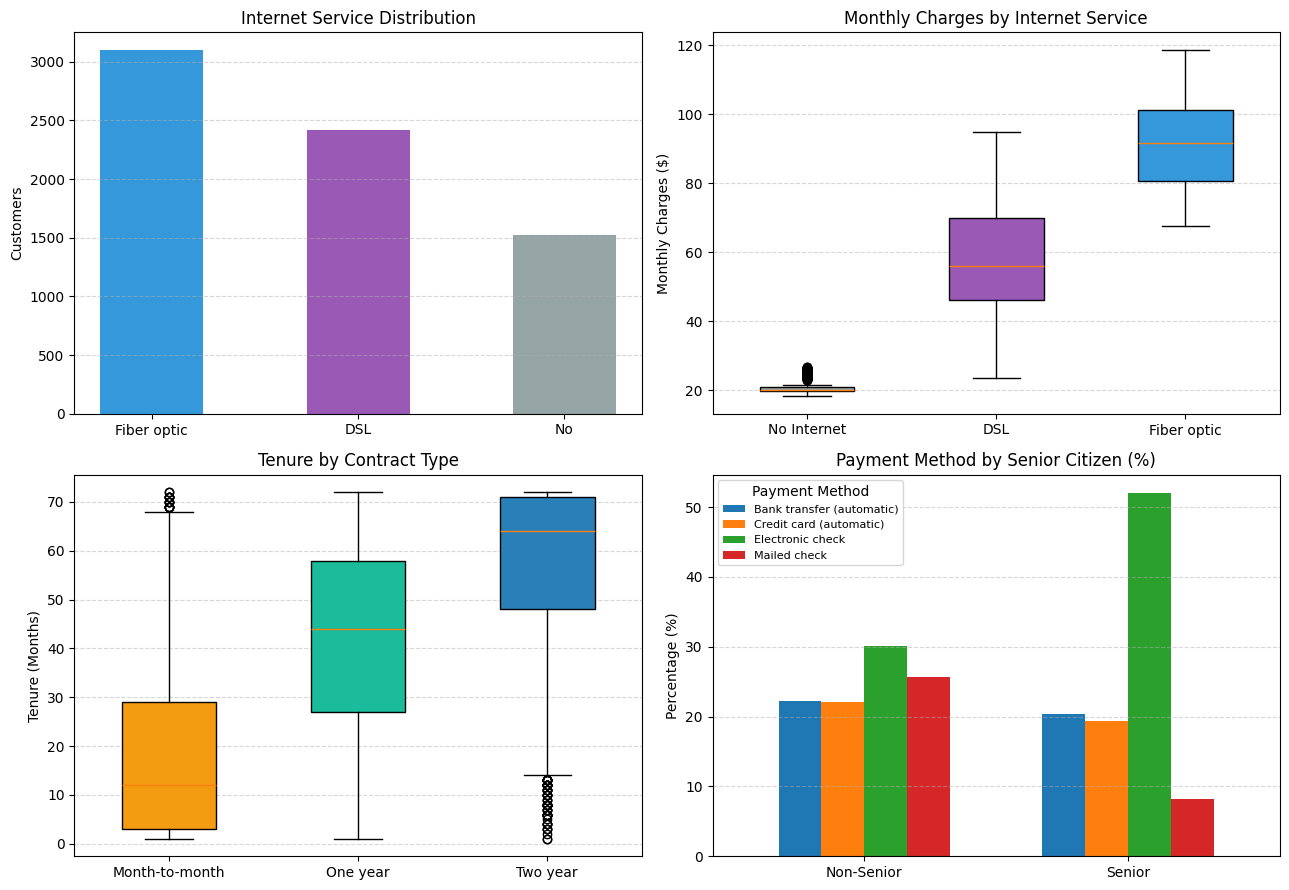

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Telco_Customer_Churn_Cleaned.csv')

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

internet_counts = df['InternetService'].value_counts()
axes[0, 0].bar(internet_counts.index, internet_counts.values, color=['#3498db', '#9b59b6', '#95a5a6'], width=0.5)
axes[0, 0].set_title('Internet Service Distribution')
axes[0, 0].set_ylabel('Customers')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

dsl_charges = df[df['InternetService'] == 'DSL']['MonthlyCharges']
fiber_charges = df[df['InternetService'] == 'Fiber optic']['MonthlyCharges']
no_net_charges = df[df['InternetService'] == 'No']['MonthlyCharges']
bp1 = axes[0, 1].boxplot([no_net_charges, dsl_charges, fiber_charges], labels=['No Internet', 'DSL', 'Fiber optic'], patch_artist=True, widths=0.5)
for patch, color in zip(bp1['boxes'], ['#95a5a6', '#9b59b6', '#3498db']):
    patch.set_facecolor(color)
axes[0, 1].set_title('Monthly Charges by Internet Service')
axes[0, 1].set_ylabel('Monthly Charges ($)')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

t_m2m = df[df['Contract'] == 'Month-to-month']['tenure']
t_1yr = df[df['Contract'] == 'One year']['tenure']
t_2yr = df[df['Contract'] == 'Two year']['tenure']
bp2 = axes[1, 0].boxplot([t_m2m, t_1yr, t_2yr], labels=['Month-to-month', 'One year', 'Two year'], patch_artist=True, widths=0.5)
for patch, color in zip(bp2['boxes'], ['#f39c12', '#1abc9c', '#2980b9']):
    patch.set_facecolor(color)
axes[1, 0].set_title('Tenure by Contract Type')
axes[1, 0].set_ylabel('Tenure (Months)')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

senior_pay = pd.crosstab(df['SeniorCitizen'], df['PaymentMethod'], normalize='index') * 100
senior_pay.index = ['Non-Senior', 'Senior']
senior_pay.plot(kind='bar', ax=axes[1, 1], width=0.65)
axes[1, 1].set_title('Payment Method by Senior Citizen (%)')
axes[1, 1].set_ylabel('Percentage (%)')
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].legend(title='Payment Method', fontsize=8)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()